# Lempel-Ziv Basket Trading Model

This notebook develops a momentum/regime-based basket trading strategy using the **Lempel-Ziv (LZ) Complexity** metric. 
It mirrors the architecture of a Hurst Exponent model but replaces the mathematical engine.

## Hypothesis
If an asset's rolling returns exhibit low LZ complexity (high predictability/structure), it is trending or mean-reverting in a predictable way. If LZ complexity is high (random noise), the asset is unpredictable. We want to allocate capital to the most structurally predictable assets and take refuge in a risk-off asset if all risk assets are too complex/random.

## Strategy Rules
1. **Universe**: Risk-On [`BTC-USD`, `QQQ`, `SPY`, `AAPL`, `TSLA`, `GLD`, `NVDA`, `AMZN`, `XLE`] + Risk-Off [`TLT`].
2. **Metric**: 63-day rolling Normalized Lempel-Ziv Complexity on binarized returns (1 for up, 0 for down).
3. **Selection**: Every 10 days, select the top 3 risk assets with the *lowest* LZ complexity, provided $LZ < 0.95$.
4. **Allocation**: Equal weight to selected risk-on assets. Any shortfall from the 3 slots is allocated to `TLT`.
5. **Execution**: Signals are applied with a 1-day lag to prevent lookahead bias.



In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.style.use('dark_background')



c:\Users\vansh\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.6.2) or chardet (6.0.0.post1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


---
## Part 1: Data Acquisition



In [2]:
# 1. Define Universe and Parameters
RISK_ON = ['BTC-USD', 'QQQ', 'SPY', 'AAPL', 'TSLA', 'GLD', 'NVDA', 'AMZN', 'XLE']
RISK_OFF = 'TLT'
UNIVERSE = RISK_ON + [RISK_OFF]

START_DATE = '2018-01-01'
END_DATE = '2025-01-01'

# Strategy Parameters
LZ_WINDOW = 84      # Lookback for LZ complexity (approx 4 months)
REBAL_PERIOD = 10   # Rebalance every 10 trading days
TOP_N = 2           # Max number of risk assets to hold
LZ_THRESHOLD = 0.99  # Relaxed LZ to consider an asset 'predictable'



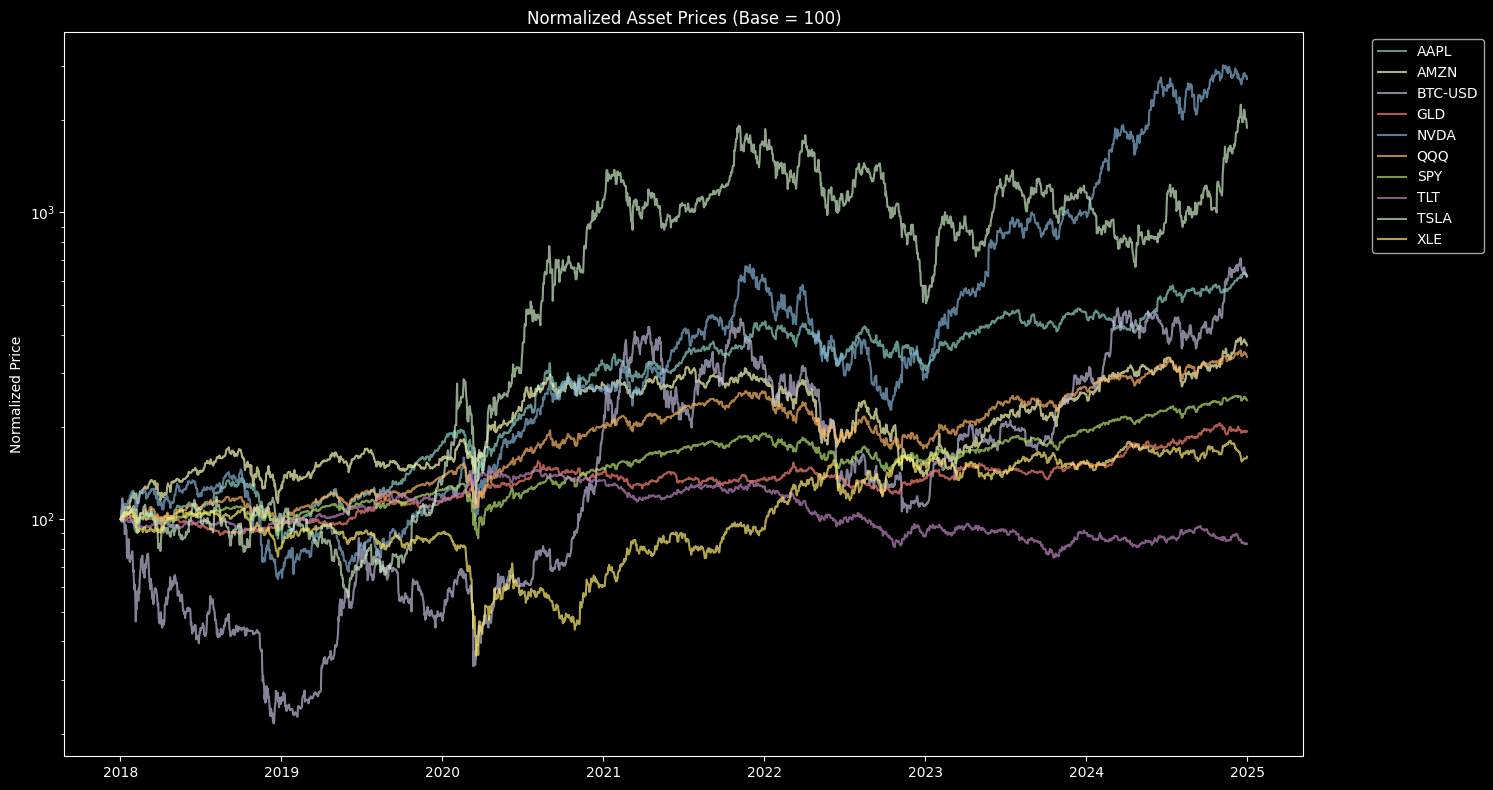

In [3]:
# 2. Download Data
print(f"Downloading data for {len(UNIVERSE)} assets...")
data = yf.download(UNIVERSE, start=START_DATE, end=END_DATE, progress=False)['Close']
data = data.ffill().dropna()

# Normalize prices to 100 at start for visualization
normalized_prices = (data / data.iloc[0]) * 100

plt.figure(figsize=(15, 8))
for col in normalized_prices.columns:
    plt.plot(normalized_prices.index, normalized_prices[col], label=col, alpha=0.7)
    
plt.title('Normalized Asset Prices (Base = 100)')
plt.ylabel('Normalized Price')
plt.yscale('log')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()



---
## Part 2: Lempel-Ziv Complexity Calculation
We define the functions to calculate the normalized LZ complexity of a binary string, then apply it on a rolling window over the binarized returns of our assets.



In [4]:
# 3. Define LZ Complexity Functions
def lz_complexity(binary_string):
    """Computes raw LZ76 complexity."""
    if len(binary_string) == 0: return 0
    i, k, l = 0, 1, 1
    complexity = 1
    n = len(binary_string)
    while True:
        if i + k > n: break
        substring = binary_string[i:i+k]
        history = binary_string[0:i+k-1]
        if substring in history:
            k += 1
        else:
            complexity += 1
            i += k
            k = 1
    return complexity

def normalized_lz(binary_string):
    """Normalized Lempel-Ziv complexity."""
    n = len(binary_string)
    if n < 2: return 0
    raw_c = lz_complexity(binary_string)
    max_c = n / np.log2(n)
    return raw_c / max_c

def rolling_lz(series):
    """Helper to apply LZ on a rolling pandas window."""
    b_str = "".join(series.astype(int).astype(str).values)
    return normalized_lz(b_str)



Calculating rolling 84-day LZ Complexity...
LZ Calculation Complete!


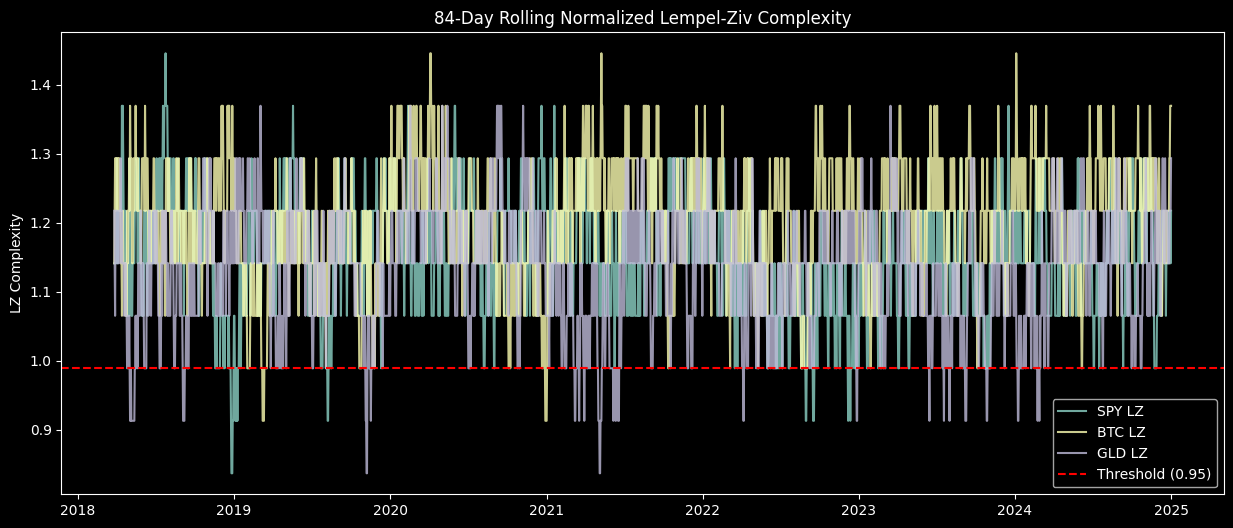

In [5]:
# 4. Compute Daily Returns and Binarize
returns = data.pct_change().dropna()
# Binarize: 1 if return > 0, else 0
binary_returns = (returns > 0).astype(int)

# 5. Calculate Rolling LZ Complexity
print(f"Calculating rolling {LZ_WINDOW}-day LZ Complexity...")
rolling_lz_df = binary_returns.rolling(window=LZ_WINDOW).apply(rolling_lz, raw=False)
rolling_lz_df = rolling_lz_df.dropna()
print("LZ Calculation Complete!")

# Plot LZ Complexity for a few assets
plt.figure(figsize=(15, 6))
plt.plot(rolling_lz_df.index, rolling_lz_df['SPY'], label='SPY LZ', alpha=0.8)
plt.plot(rolling_lz_df.index, rolling_lz_df['BTC-USD'], label='BTC LZ', alpha=0.8)
plt.plot(rolling_lz_df.index, rolling_lz_df['GLD'], label='GLD LZ', alpha=0.8)
plt.axhline(LZ_THRESHOLD, color='red', linestyle='--', label='Threshold (0.95)')
plt.title(f'{LZ_WINDOW}-Day Rolling Normalized Lempel-Ziv Complexity')
plt.ylabel('LZ Complexity')
plt.legend()
plt.show()



---
## Part 3: Strategy Implementation (LZ + RSI Filter)
We step through time. At each rebalance interval, we find the risk assets that exhibit bullish momentum (**RSI > 40**) and have the highest predictability (**lowest LZ complexity**). We filter those above the threshold, pick the top N, and allocate evenly. The rest goes to `TLT`.



<Figure size 1500x600 with 0 Axes>

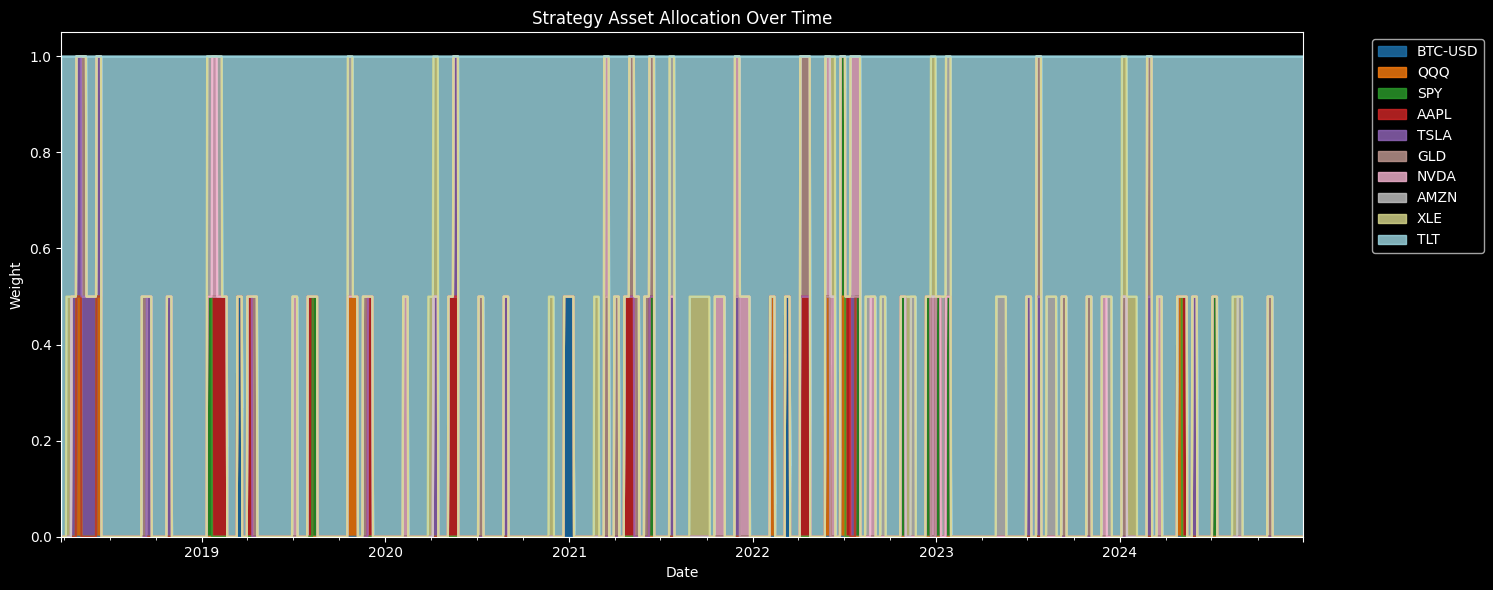

In [6]:
# 6. Calculate RSI and Generate Target Weights
# Calculate 14-day RSI manually to avoid dependencies
delta = data.diff()
up, down = delta.copy(), delta.copy()
up[up < 0] = 0
down[down > 0] = 0
roll_up = up.ewm(com=13, adjust=False).mean() # 14-1
roll_down = down.abs().ewm(com=13, adjust=False).mean()
rs = roll_up / roll_down
rsi_df = 100.0 - (100.0 / (1.0 + rs))

# Align dates across dataframes
valid_dates = rolling_lz_df.index.intersection(rsi_df.index)

# Ensure the validation period starts EXACTLY at 2018-01-01 to match optimizations
valid_dates = valid_dates[valid_dates >= '2018-01-01']

# Initialize weights as explicitly float to prevent downstream plotting TypeErrors
target_weights = pd.DataFrame(0.0, index=valid_dates, columns=UNIVERSE, dtype=float)

for i in range(len(valid_dates)):
    date = valid_dates[i]
    
    # Only rebalance every REBAL_PERIOD days
    if i % REBAL_PERIOD == 0:
        # Get current LZ and RSI values for Risk-On universe
        current_lz = rolling_lz_df.loc[date, RISK_ON].astype(float)
        current_rsi = rsi_df.loc[date, RISK_ON].astype(float)
        
        # Filter for eligible assets (LZ < Threshold AND RSI > 40)
        eligible_mask = (current_lz < LZ_THRESHOLD) & (current_rsi > 40)
        eligible_assets = [asset for asset in RISK_ON if eligible_mask[asset]]
        
        # Rank by HIGHEST RSI (strongest trend) among the predictable assets
        if len(eligible_assets) > 0:
            selected = current_rsi[eligible_assets].sort_values(ascending=False).head(TOP_N)
        else:
            selected = pd.Series(dtype=float)
        
        # Calculate weights
        num_selected = len(selected)
        if num_selected > 0:
            weight_per_asset = 1.0 / TOP_N
            for asset in selected.index:
                target_weights.loc[date, asset] = weight_per_asset
                
            # Allocate remainder to Risk-Off
            risk_off_weight = 1.0 - (num_selected * weight_per_asset)
            if risk_off_weight > 0:
                target_weights.loc[date, RISK_OFF] = risk_off_weight
        else:
            # Nothing is predictable and trending up, 100% Risk-Off
            target_weights.loc[date, RISK_OFF] = 1.0
    else:
        # Carry forward previous weights
        if i > 0:
            target_weights.loc[date] = target_weights.loc[valid_dates[i-1]]
        else:
            target_weights.loc[date, RISK_OFF] = 1.0 # Default start

# Plot allocation over time
plt.figure(figsize=(15, 6))
target_weights.plot.area(figsize=(15,6), colormap='tab20', alpha=0.8)
plt.title('Strategy Asset Allocation Over Time')
plt.ylabel('Weight')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()



---
## Part 4: Strategy Performance
Finally, we apply a 1-day lag to the weights (to avoid lookahead bias), calculate strategy returns, and compare against an equal-weight benchmark.



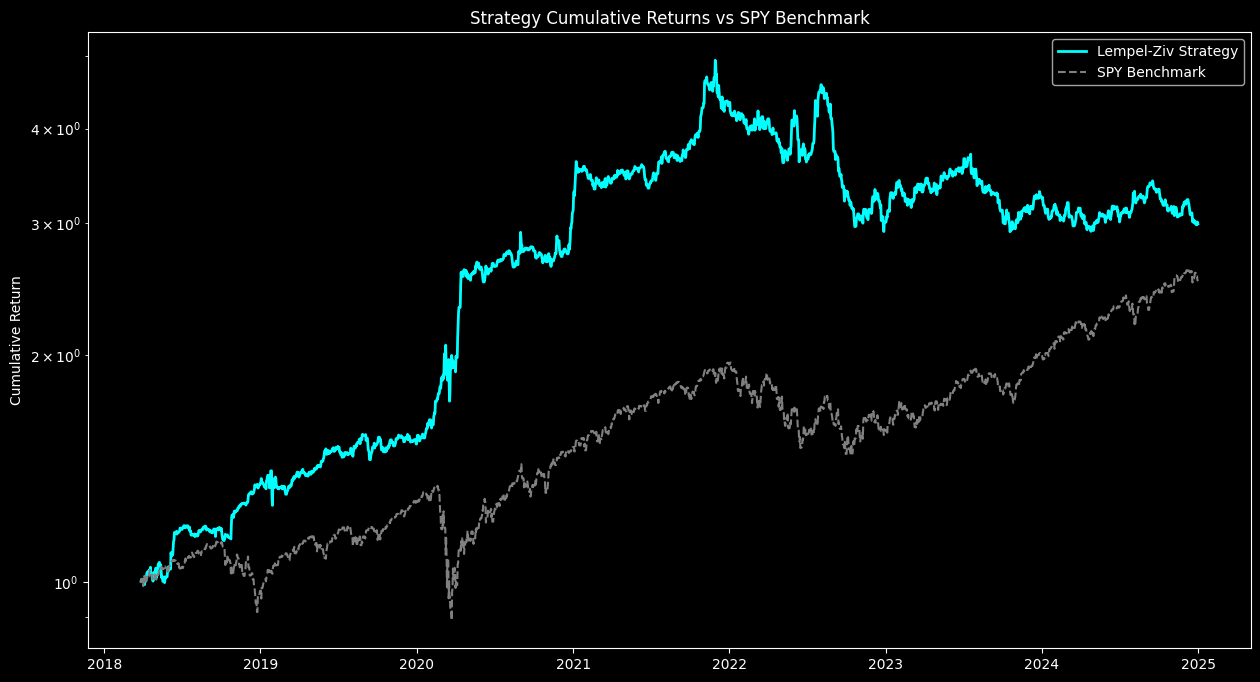

In [7]:
# 7. Apply 1-Day Lag and Calculate Returns
# Shift weights by 1 day to execute at next day's close
executed_weights = target_weights.shift(1).dropna()

# Align returns with executed weights
aligned_returns = returns.loc[executed_weights.index]

# Calculate Strategy Returns
strategy_returns = (executed_weights * aligned_returns).sum(axis=1)

# Create SPY Buy & Hold Benchmark
bm_returns = aligned_returns['SPY']

# Calculate Cumulative Returns
strategy_cum = (1 + strategy_returns).cumprod()
bm_cum = (1 + bm_returns).cumprod()

plt.figure(figsize=(15, 8))
plt.plot(strategy_cum.index, strategy_cum, label='Lempel-Ziv Strategy', color='cyan', linewidth=2)
plt.plot(bm_cum.index, bm_cum, label='SPY Benchmark', color='gray', linestyle='--')
plt.title('Strategy Cumulative Returns vs SPY Benchmark')
plt.ylabel('Cumulative Return')
plt.yscale('log')
plt.legend()
plt.show()



,LZ Strategy,SPY Benchmark
Total Return,199.02%,150.86%
CAGR,17.58%,14.57%
Annual Volatility,17.21%,16.14%
Sharpe Ratio (Rf=2%),0.91,0.78
Sortino Ratio,1.11,0.79
Max Drawdown,-40.79%,-33.72%


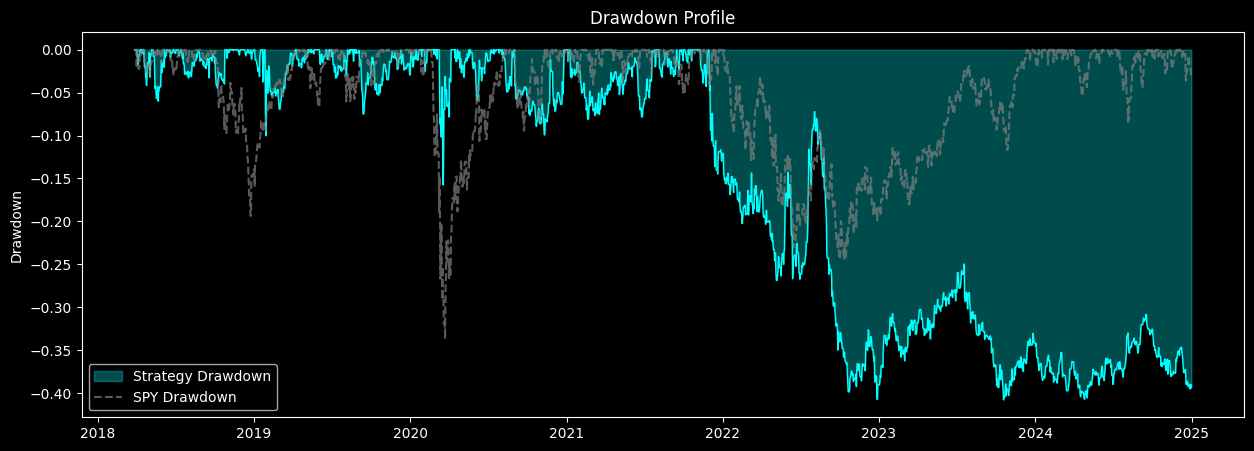

In [8]:
# 8. Performance Metrics
def calculate_metrics(returns_series):
    cum_ret = (1 + returns_series).prod() - 1
    # CAGR
    days = (returns_series.index[-1] - returns_series.index[0]).days
    cagr = (1 + cum_ret) ** (365.25 / days) - 1
    
    # Volatility and Sharpe
    vol = returns_series.std() * np.sqrt(252)
    sharpe = (cagr - 0.02) / vol if vol != 0 else 0
    
    # Max Drawdown
    cum_roll_max = (1 + returns_series).cumprod().cummax()
    drawdown = (1 + returns_series).cumprod() / cum_roll_max - 1
    max_dd = drawdown.min()
    
    # Sortino
    neg_vol = returns_series[returns_series < 0].std() * np.sqrt(252)
    sortino = (cagr - 0.02) / neg_vol if neg_vol != 0 else 0
    
    return pd.Series({
        'Total Return': f"{cum_ret*100:.2f}%",
        'CAGR': f"{cagr*100:.2f}%",
        'Annual Volatility': f"{vol*100:.2f}%",
        'Sharpe Ratio (Rf=2%)': f"{sharpe:.2f}",
        'Sortino Ratio': f"{sortino:.2f}",
        'Max Drawdown': f"{max_dd*100:.2f}%"
    })

metrics_df = pd.DataFrame({
    'LZ Strategy': calculate_metrics(strategy_returns),
    'SPY Benchmark': calculate_metrics(bm_returns)
})

display(metrics_df)

# Ensure series are numeric to prevent matplotlib TypeError 'isfinite' not supported
strategy_cum = pd.to_numeric(strategy_cum, errors='coerce').fillna(1.0)
bm_cum = pd.to_numeric(bm_cum, errors='coerce').fillna(1.0)

# Plot Drawdowns
cum_roll_max_strat = strategy_cum.cummax()
dd_strat = strategy_cum / cum_roll_max_strat - 1

cum_roll_max_bm = bm_cum.cummax()
dd_bm = bm_cum / cum_roll_max_bm - 1

plt.figure(figsize=(15, 5))
plt.fill_between(dd_strat.index, dd_strat.astype(float), 0, color='cyan', alpha=0.3, label='Strategy Drawdown')
plt.plot(dd_strat.index, dd_strat.astype(float), color='cyan', linewidth=1)
plt.plot(dd_bm.index, dd_bm.astype(float), color='gray', linestyle='--', alpha=0.7, label='SPY Drawdown')
plt.title('Drawdown Profile')
plt.ylabel('Drawdown')
plt.legend()
plt.show()

